# 04 - Error analysis

**Research question:** Which generators do CLAP, MERT and MuQ confuse? Do their errors overlap, and what properties of prompts or audio might be associated with those mistakes?

**Input:** `results/baseline_full_top5.csv`,<br>
`results/baseline_full_top5_predictions.csv`, <br> 
`data/interim/split_metadata.csv`;<br>
`optionally data/interim/handcrafted_features_full.csv` for acoustic diagnostics. These files are generated in notebooks 01–03.

*This is a post-hoc error analysis of the full FakeMusicCaps test set (4,145 clips). No model retraining, no embedding extraction, and no model-selection experiments here.*

In [7]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

In [28]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
DATASET_MODE = "full"

def results_file(stem):
    return RESULTS_DIR / f"{stem}_{DATASET_MODE}.csv"

In [22]:
top5_path = RESULTS_DIR / f"baseline_{DATASET_MODE}_top5.csv"
pred_path = RESULTS_DIR / f"baseline_{DATASET_MODE}_top5_predictions.csv"
meta_path = PROJECT_ROOT / "data" / "interim" / ("split_metadata.csv" if DATASET_MODE == "full" else "pilot_metadata.csv")
for p in [top5_path, pred_path, meta_path]:
    if not p.exists():
        raise FileNotFoundError(f"Required file not found: {p}")

In [ ]:
top5 = pd.read_csv(top5_path).sort_values("validation_rank").reset_index(drop=True)
predictions = pd.read_csv(pred_path, dtype={"track_id": str})
metadata = pd.read_csv(meta_path, dtype={"track_id": str})
model_ids = top5["model_id"].tolist()
model_names = dict(zip(top5["model_id"], top5["Representation"] + " + " + top5["Model"]))
selected_id = model_ids[0]
reference_id = next((m for m in model_ids if m.startswith("clap__")), model_ids[-1])
class_names = sorted(metadata["generator"].unique().tolist())
keys = ["track_id", "generator", "split"]

In [ ]:
for model_id in model_ids:
    rows = predictions[predictions["model_id"] == model_id]
    observed = pd.MultiIndex.from_frame(rows[keys])

predictions["is_error"] = predictions["generator"].ne(predictions["predicted_generator"])
test_predictions = predictions[predictions["split"] == "test"].copy()
wrong = test_predictions[test_predictions["is_error"]].copy()
n_test = len(test_predictions[test_predictions["model_id"] == selected_id])
summary = top5[["validation_rank", "model_id", "validation_macro_f1", "test_macro_f1", "test_minus_validation_macro_f1"]].copy()
summary["model"] = summary["model_id"].map(model_names)
summary["test_errors"] = summary["model_id"].map(test_predictions.groupby("model_id")["is_error"].sum()).astype(int)
summary["test_error_rate_%"] = (100 * summary["test_errors"] / n_test).round(2)
display(summary[["validation_rank", "model", "validation_macro_f1", "test_macro_f1", "test_errors", "test_error_rate_%", "test_minus_validation_macro_f1"]].round(4))
print(f"Same held-out test set for all models: {n_test:,} clips; selected by validation: {model_names[selected_id]}")

,validation_rank,model,validation_macro_f1,test_macro_f1,test_errors,test_error_rate_%,test_minus_validation_macro_f1
0,1,MuQ + SVM,0.9862,0.9896,43,1.04,0.0034
1,2,MuQ + Logistic Regression,0.9800,0.9836,68,1.64,0.0036
2,3,MERT + SVM,0.9675,0.9526,197,4.75,-0.0149
3,4,MERT + Logistic Regression,0.9628,0.9563,181,4.37,-0.0065
4,5,CLAP + SVM,0.9234,0.9167,344,8.30,-0.0067


Same held-out test set for all models: 4,145 clips; selected by validation: MuQ + SVM


**MuQ + SVM** makes 43/4145 errors (1.04%), versus 344/4145 (8.30%) for **CLAP + SVM**. These are closed-set FakeMusicCaps results. The choice of representation is more consequential here than the relatively small difference between MuQ classifiers

## 1. Per-class precision / recall / F1 (**test**)
**Recall** = proportion of the true clips from this generator correctly recognised; <br>
**Precision** = proportion of predictions of this generator that are correct; <br>
**F1** сompare class-level F1 across models, then inspect the selected model's recall and number of missed clips; <br>
**Support** = number of true test clips.

In [25]:
per_class_rows = []
for model_id in model_ids:
    group = test_predictions[test_predictions["model_id"] == model_id]
    report = classification_report(group["generator"], group["predicted_generator"], labels=class_names, output_dict=True, zero_division=0)
    for generator in class_names:
        r = report[generator]
        per_class_rows.append(dict(model_id=model_id, generator=generator,
                                   precision=r["precision"], recall=r["recall"], f1=r["f1-score"], support=int(r["support"])))
per_class = pd.DataFrame(per_class_rows)
per_class["missed_clips"] = (per_class["support"] * (1 - per_class["recall"])).round().astype(int)
comparison = per_class.pivot(index="generator", columns="model_id", values="f1").rename(columns=model_names)
display(comparison.round(3))
print("Selected model: precision, recall, F1, and missed clips")
display(per_class[per_class["model_id"] == selected_id][["generator", "precision", "recall", "f1", "missed_clips", "support"]].round(4))
per_class.to_csv(results_file("error_analysis_top5_per_class"), index=False)

model_id,CLAP + SVM,MERT + Logistic Regression,MERT + SVM,MuQ + Logistic Regression,MuQ + SVM
generator,,,,,
MusicGen_medium,0.945,0.955,0.934,0.987,0.993
audioldm2,0.870,0.935,0.938,0.978,0.985
musicldm,0.866,0.957,0.952,0.979,0.986
mustango,0.913,0.953,0.962,0.981,0.990
stable_audio_open,0.990,0.981,0.978,0.992,0.995


Selected model: precision, recall, F1, and missed clips


,generator,precision,recall,f1,missed_clips,support
0,MusicGen_medium,0.9928,0.9928,0.9928,6,829
1,audioldm2,0.9774,0.9928,0.9850,6,829
2,musicldm,0.9879,0.9843,0.9861,13,829
3,mustango,0.9963,0.9831,0.9897,14,829
4,stable_audio_open,0.9940,0.9952,0.9946,4,829


For **MuQ + SVM**, `stable_audio_open` has the highest class F1, while `audioldm2` has the lowest F1. Importantly, `audioldm2` is missed only 6 times; its comparatively lower F1 is mainly affected by incorrect predictions into that class. The greatest numbers of missed true clips for **MuQ + SVM** are mustango (14) and musicldm (13). This distinction is why F1, precision, and recall should not be conflated.

## 2. Confusion matrices

Per-class metrics do not tell us which other generator is predicted instead. Here every row is the true generator and every column the predicted generator.

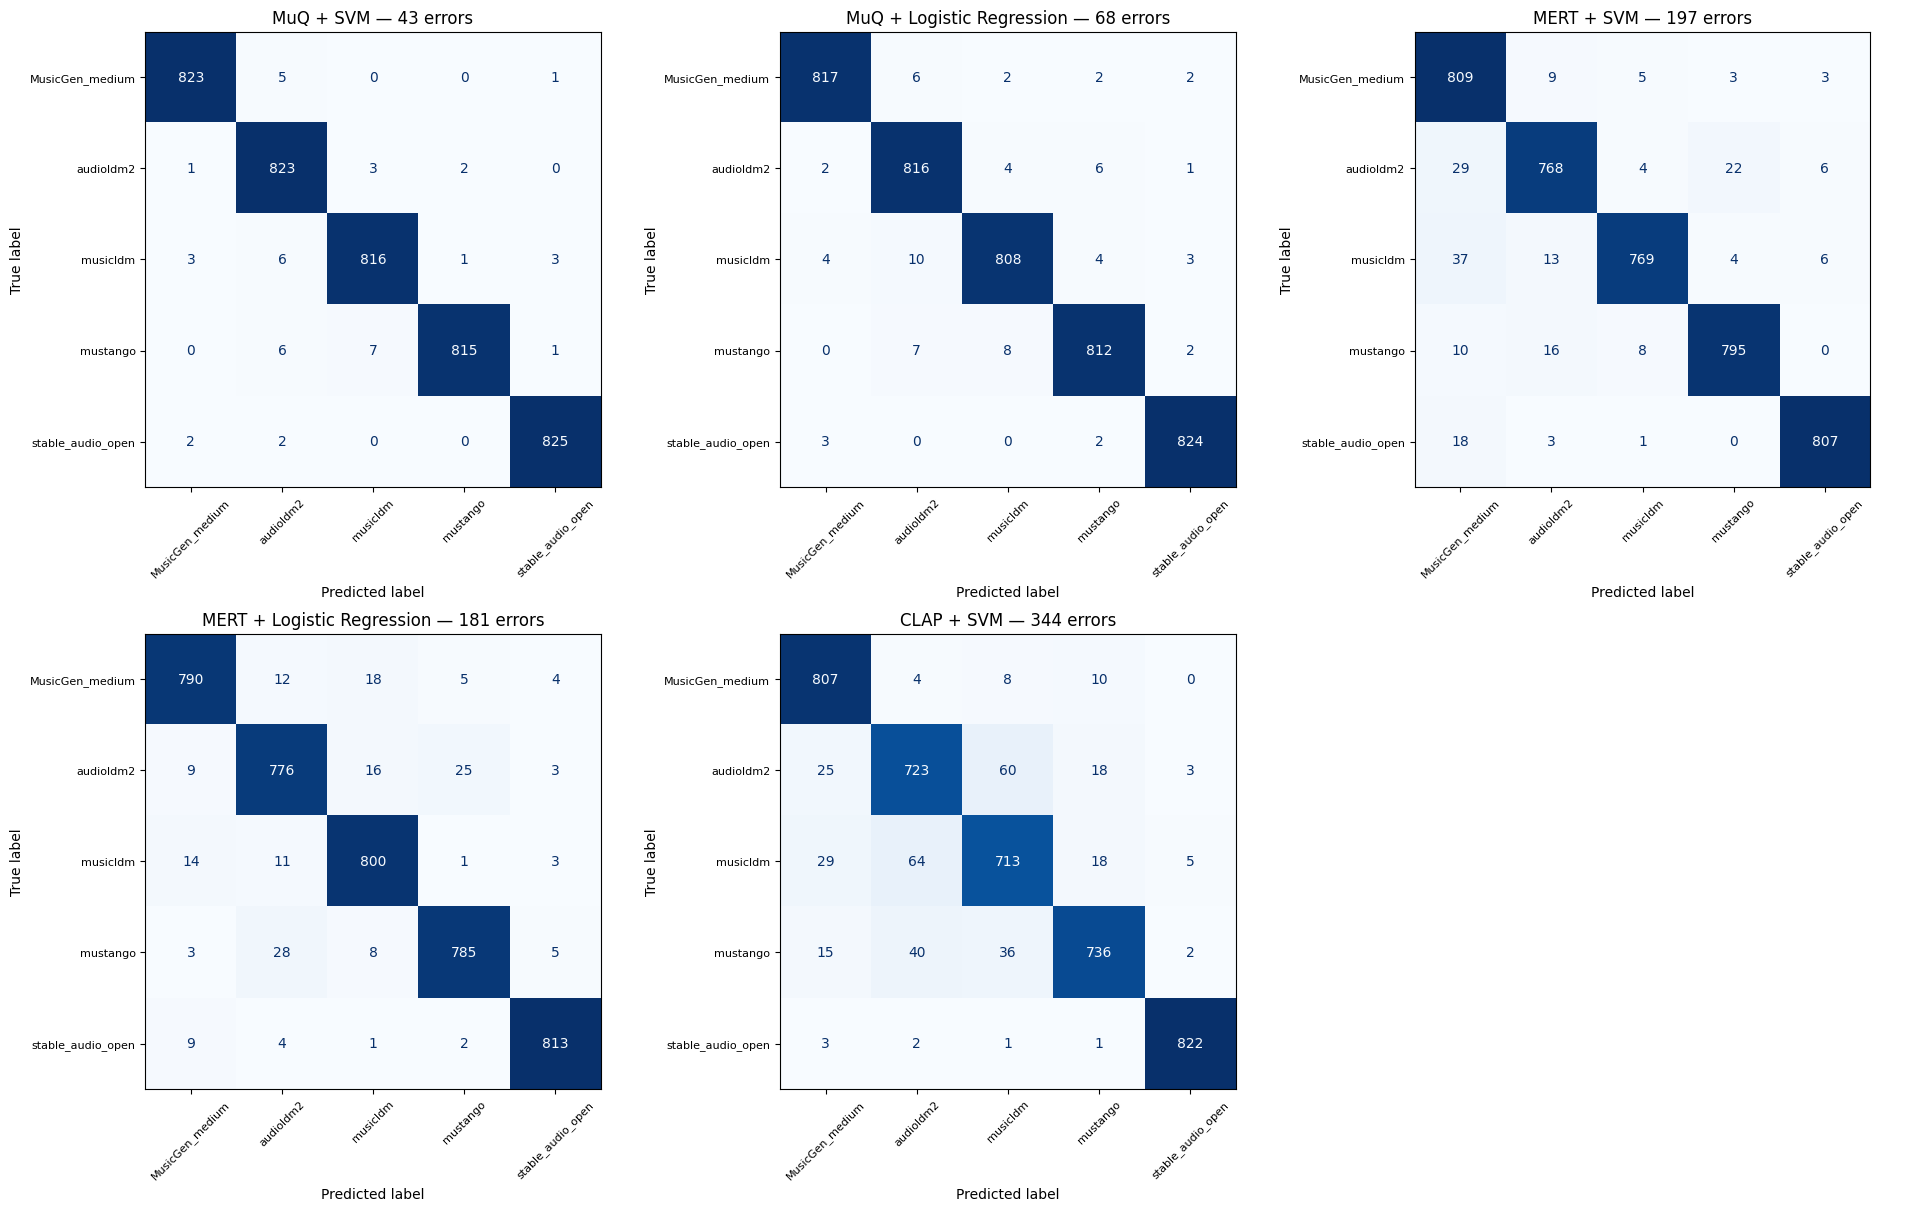

In [14]:
error_counts = predictions[predictions.split == "test"].groupby("model_id").is_error.sum().astype(int)
fig, axes = plt.subplots(2, 3, figsize=(19, 12), constrained_layout=True)
matrices = {}
for ax, m in zip(axes.flat, model_ids):
    subset = predictions[(predictions.model_id == m) & (predictions.split == "test")]
    matrix = confusion_matrix(subset.generator, subset.predicted_generator, labels=class_names)
    matrices[m] = matrix
    ConfusionMatrixDisplay(matrix, display_labels=class_names).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d", xticks_rotation=45
    )
    ax.tick_params(labelsize=8)
    ax.set_title(f"{model_names[m]} — {int(error_counts[m])} errors")
for ax in list(axes.flat)[len(model_ids):]:
    ax.axis("off")
fig.savefig(RESULTS_DIR / "figures" / f"top5_confusion_matrices_{DATASET_MODE}.png", dpi=150)
plt.show()


## 3. Most frequent directed and undirected confusions

A → B and B → A are different errors. Count both the most common directions and the combined pairs A ↔ B, separately for each model. The percentage is relative to that model's total number of errors.

In [31]:
error_counts = test_predictions.groupby("model_id")["is_error"].sum().astype(int)
directed = (wrong.groupby(["model_id", "generator", "predicted_generator"])
            .size().rename("errors").reset_index())
wrong["unordered_pair"] = wrong.apply(lambda r: " ↔ ".join(sorted((r["generator"], r["predicted_generator"]))), axis=1)
undirected = wrong.groupby(["model_id", "unordered_pair"]).size().rename("errors").reset_index()
rows = []
for model_id in model_ids:
    d = directed[directed["model_id"] == model_id].sort_values("errors", ascending=False).iloc[0]
    u = undirected[undirected["model_id"] == model_id].sort_values("errors", ascending=False).iloc[0]
    rows.append(dict(model=model_names[model_id], top_direction=f"{d['generator']} → {d['predicted_generator']}",
                     direction_errors=int(d["errors"]), top_pair=u["unordered_pair"],
                     pair_errors=int(u["errors"]), pair_share_of_errors_pct=100*u["errors"]/error_counts[model_id]))
confusion_summary = pd.DataFrame(rows)
display(confusion_summary.round(1))
directed.to_csv(results_file("error_analysis_top5_directed"), index=False)
undirected.to_csv(results_file("error_analysis_top5_undirected"), index=False)

,model,top_direction,direction_errors,top_pair,pair_errors,pair_share_of_errors_pct
0,MuQ + SVM,mustango → musicldm,7,audioldm2 ↔ musicldm,9,20.9
1,MuQ + Logistic Regression,musicldm → audioldm2,10,audioldm2 ↔ musicldm,14,20.6
2,MERT + SVM,musicldm → MusicGen_medium,37,MusicGen_medium ↔ musicldm,42,21.3
3,MERT + Logistic Regression,mustango → audioldm2,28,audioldm2 ↔ mustango,53,29.3
4,CLAP + SVM,musicldm → audioldm2,64,audioldm2 ↔ musicldm,124,36.0


**CLAP + SVM** confuses `audioldm2` ↔ `musicldm` 124 times (36.0% of its 344 errors). For **MERT + SVM**, the most common pair is `MusicGen_medium` ↔ `musicldm` (42 errors); for **MERT + Logistic Regression** it is `audioldm2` ↔ `mustango` (53 errors). **MuQ + SVM's** most common pair, `audioldm2` ↔ `musicldm`, contributes only 9 errors. No single confusion pattern explains all models.

## 4. Error overlap: are the same audio clips difficult for multiple models?
Each (track_id, true generator) denotes one clip; Count mistakes made by 0–5 models on the same clip to keep the presentation compact, compare each other model's shared errors with **MuQ + SVM**.

In [ ]:
error_wide = test_predictions.pivot(index=["track_id", "generator"], columns="model_id", values="is_error")
error_wide = error_wide[model_ids].astype(bool)
error_wide["n_models_wrong"] = error_wide[model_ids].sum(axis=1)
shared = error_wide.reset_index()
error_distribution = (shared["n_models_wrong"].value_counts()
                      .reindex(range(len(model_ids)+1), fill_value=0)
                      .rename_axis("models_wrong").reset_index(name="n_clips"))
display(error_distribution)

rows = []
for model_id in model_ids:
    mask = error_wide[model_id]
    both = int((mask & error_wide[selected_id]).sum())
    union = int((mask | error_wide[selected_id]).sum())
    rows.append(dict(model=model_names[model_id], errors=int(mask.sum()),
                     unique_to_this_model=int((mask & (error_wide["n_models_wrong"] == 1)).sum()),
                     also_wrong_in_MuQ_SVM=both, jaccard_with_MuQ_SVM=both/union if union else np.nan))
overlap_summary = pd.DataFrame(rows)
display(overlap_summary.round(3))
shared.to_csv(results_file("error_analysis_top5_shared_errors"), index=False)

,models_wrong,n_clips
0,0,3539
1,1,460
2,2,89
3,3,38
4,4,14
5,5,5


,model,errors,unique_to_this_model,also_wrong_in_MuQ_SVM,jaccard_with_MuQ_SVM
0,MuQ + SVM,43,9,43,1.000
1,MuQ + Logistic Regression,68,25,21,0.233
2,MERT + SVM,197,81,21,0.096
3,MERT + Logistic Regression,181,87,14,0.067
4,CLAP + SVM,344,258,22,0.060


- 3,539/4,145 clips are correct for all five models;
- five clips are wrong for all five, and 57 clips are wrong for at least three.

Only 9/43 **MuQ + SVM** errors are unique to that model, whereas **258/344** **CLAP + SVM** errors are unique among these Top-5 models. This suggests meaningful differences in what the representations capture.

## 5. Inspect concrete clips and the same prompt across generators
(a) the five clips misclassified by all models and <br> 
(b) a few mistakes unique to **MuQ + SVM**. 

For a selected difficult `track_id`, also inspect predictions for all five generator versions of the same prompt. This tests whether difficulty is prompt-wide or specific to a generated version.

In [ ]:
meta_cols = ["track_id", "generator", "split"] + [c for c in ["caption", "path"] if c in metadata.columns]
clip_meta = metadata[metadata["split"] == "test"][meta_cols]
universally_wrong = shared[shared["n_models_wrong"] == len(model_ids)].copy()
muq_unique = shared[(shared[selected_id]) & (shared["n_models_wrong"] == 1)].copy()
focus = pd.concat([universally_wrong, muq_unique.head(5)], ignore_index=True)
focus = focus.merge(clip_meta, on=["track_id", "generator"], how="left", validate="one_to_one")
focus["case"] = ["wrong_for_all_5"] * len(universally_wrong) + ["muq_svm_only"] * min(len(muq_unique), 5)
show_cols = [c for c in ["case", "track_id", "generator", "caption"] if c in focus.columns]
display(focus[show_cols].style.set_properties(subset=["caption"], **{"white-space": "normal"}) if "caption" in focus.columns else focus[show_cols])
focus.to_csv(results_file("error_analysis_focus_clips"), index=False)

if not universally_wrong.empty:
    focus_track_id = universally_wrong.iloc[0]["track_id"]
    same_prompt = test_predictions[test_predictions["track_id"] == focus_track_id].copy()
    same_prompt["prediction"] = np.where(same_prompt["is_error"], "✗ " + same_prompt["predicted_generator"], "✓")
    by_generator = same_prompt.pivot(index="generator", columns="model_id", values="prediction").rename(columns=model_names)
    print(f"Predictions for every generated version of one shared prompt: track_id={focus_track_id}")
    if "caption" in clip_meta:
        caption = clip_meta.loc[clip_meta["track_id"] == focus_track_id, "caption"].dropna()
        if not caption.empty:
            print("Prompt:", caption.iloc[0])
    display(by_generator)

,case,track_id,generator,caption
0,wrong_for_all_5,3OWArQGgmm0,audioldm2,"The low quality recording features an electric guitar melody, with echoing wobble effect on, that occasionally distorts. It sounds like the player is trying out an effect for his guitar."
1,wrong_for_all_5,E6JR3htwgyE,mustango,The song is instrumental. The song is medium with a bell ringing with echoes in the room. There is no other instrumentation. The song is healing and relaxing in nature. The audio quality is bad with ambient room noise.
2,wrong_for_all_5,Z2c1npe5AYY,mustango,"The low quality recording features a deep tone singing bowl resonance and a bowl hit impact. It sounds relaxing, calming and hypnotic."
3,wrong_for_all_5,nqcVA89BD6I,audioldm2,This song features an electric guitar played using a clean tone. Octaves are played in this clip. The first note is a slide up two frets followed by an ascending lick using octaves throughout the song. There are no other instruments in this song. A buzz is heard probably from the hi-gain amp that is being used. There is no voice in this song. This song can be used in a guitar instruction video.
4,wrong_for_all_5,uYCAxX2F6DA,mustango,This audio contains someone playing a tibetan bowl ringing in a high pitch. This may be playing during meditation.
5,muq_svm_only,5KvjUzQbMT4,MusicGen_medium,"Here we get to hear a hardcore metal piece. This is characterised, in part, by the rapid action on the kick drum - with notes being played at a rate of sixteenth notes on the kick. The drummer also frequents the ride cymbal. The guitar is grungy, gritty, fuzzy, heavy, deep, hardcore."
6,muq_svm_only,CH-zch2pUic,MusicGen_medium,This song contains samples of water sounds over and under water. String pads are playing a soft and calming melody in the higher register along with single pluck sounds playing a little melody on top. This song may be playing for an advertisement.
7,muq_svm_only,E6JR3htwgyE,musicldm,The song is instrumental. The song is medium with a bell ringing with echoes in the room. There is no other instrumentation. The song is healing and relaxing in nature. The audio quality is bad with ambient room noise.
8,muq_svm_only,MJtDDmS6xSY,mustango,"The low quality, noisy recording features a male throaty vocals singing and some footsteps sound effects. In the background, some dog is barking. The whole sound is panned to the left channel of the stereo image, thus the unbalanced stereo image and it sounds like a sound from TV was recorded."
9,muq_svm_only,MPxwPOOIskc,audioldm2,Quiet instrumental cover of a popular pop/rock song by an orchestra that features winds and strings trading off parts of the melody.


Predictions for every generated version of one shared prompt: track_id=3OWArQGgmm0
Prompt: The low quality recording features an electric guitar melody, with echoing wobble effect on, that occasionally distorts. It sounds like the player is trying out an effect for his guitar.


model_id,CLAP + SVM,MERT + Logistic Regression,MERT + SVM,MuQ + Logistic Regression,MuQ + SVM
generator,,,,,
MusicGen_medium,✓,✓,✓,✓,✓
audioldm2,✗ mustango,✗ musicldm,✗ mustango,✗ mustango,✗ mustango
musicldm,✓,✓,✓,✓,✓
mustango,✓,✓,✓,✓,✓
stable_audio_open,✓,✓,✓,✓,✓


All five models fail on `3OWArQGgmm0 / audioldm2`, `E6JR3htwgyE / mustango`, `uYCAxX2F6DA / mustango`, `nqcVA89BD6I / audioldm2`, and `Z2c1npe5AYY / mustango`. Some descriptions mention low-quality recordings or unusual instruments. These are candidates for listening inspection.

## 6. Prompt-description associations
The test set contains **829 prompts**, each represented by five clips. For a model, a prompt is counted as problematic if it has at least one incorrect generator version. Keyword groups come from the original captions they are not verified audio genres or sound-quality measurements. 

We display just two preselected comparisons (recording artifacts, vocals) for the best **MuQ** model and **CLAP**.

In [34]:
prompt_level = (test_predictions.groupby(["model_id", "track_id"], as_index=False)
                .agg(generators_wrong=("is_error", "sum"), n_generators=("generator", "nunique")))
assert (prompt_level["n_generators"] == len(class_names)).all()
per_prompt = (prompt_level.groupby("model_id").agg(
    prompts_with_any_error=("generators_wrong", lambda x: int((x >= 1).sum())),
    prompts_with_two_or_more_errors=("generators_wrong", lambda x: int((x >= 2).sum()))))
display(per_prompt.rename(index=model_names))
prompt_level.to_csv(results_file("error_analysis_top5_per_prompt"), index=False)

if "caption" not in metadata.columns:
    print("No captions available; skipping prompt-tag comparison")
else:
    captions = (metadata.loc[metadata["split"] == "test", ["track_id", "caption"]]
                .drop_duplicates("track_id"))
    prompt_level = prompt_level.merge(captions, on="track_id", how="left", validate="many_to_one")
    patterns = {
        "recording artifacts": r"\b(?:lo-fi|low quality|recording|noisy|distorted|crackle|static)\b",
        "vocals": r"\b(?:vocal|vocals|voice|singing|singer|chorus)\b",
        "rock/metal": r"\b(?:rock|metal|punk)\b",
        "electronic": r"\b(?:electronic|synth|techno|house|edm)\b",
        "piano": r"\b(?:piano|keyboard)\b",
        "percussion": r"\b(?:drum|drums|percussion|beat)\b",
        "guitar": r"\b(?:guitar|guitars)\b",
    }
    tags = []
    for model_id, rows in prompt_level.groupby("model_id"):
        error_any = rows["generators_wrong"].gt(0)
        for tag, pattern in patterns.items():
            contains = rows["caption"].fillna("").astype(str).str.contains(pattern, flags=re.I, regex=True)
            if int(contains.sum()) < 20 or int((~contains).sum()) < 20:
                continue
            a = int(error_any[contains].sum()); na = int(contains.sum())
            b = int(error_any[~contains].sum()); nb = int((~contains).sum())
            tags.append(dict(model_id=model_id, tag=tag, n_tagged_prompts=na, tagged_with_error=a,
                             n_other_prompts=nb, other_with_error=b,
                             error_rate_tagged_pct=100*a/na, error_rate_other_pct=100*b/nb,
                             difference_pp=100*(a/na-b/nb)))
    tag_df = pd.DataFrame(tags)
    tag_df.to_csv(results_file("error_analysis_top5_prompt_tags"), index=False)
    if tag_df.empty:
        print("No prompt tag has at least 20 examples in both groups; skipping comparisons.")
    else:
        display_cols = ["model", "tag", "tagged_with_error", "n_tagged_prompts", "error_rate_tagged_pct", "error_rate_other_pct", "difference_pp"]
        comparison = tag_df[tag_df["model_id"].isin([selected_id, reference_id]) & tag_df["tag"].isin(["recording artifacts", "vocals"])].copy()
        comparison["model"] = comparison["model_id"].map(model_names)
        display(comparison[display_cols].round(2))

,prompts_with_any_error,prompts_with_two_or_more_errors
model_id,,
CLAP + SVM,290,49
MERT + Logistic Regression,154,26
MERT + SVM,169,25
MuQ + Logistic Regression,66,2
MuQ + SVM,39,4


,model,tag,tagged_with_error,n_tagged_prompts,error_rate_tagged_pct,error_rate_other_pct,difference_pp
0,CLAP + SVM,recording artifacts,117,303,38.61,32.89,5.72
1,CLAP + SVM,vocals,73,350,20.86,45.30,-24.45
28,MuQ + SVM,recording artifacts,20,303,6.60,3.61,2.99
29,MuQ + SVM,vocals,8,350,2.29,6.47,-4.19


For **MuQ + SVM**, captions mentioning recording artifacts are associated with an error on 20/303 prompts (6.60%), versus 19/526 (3.61%) for the remaining prompts. For **CLAP + SVM** the corresponding rates are 38.61% versus 32.89%. Conversely, prompts mentioning vocals are associated with fewer prompt-level errors: 2.29% vs 6.47% for **MuQ + SVM** and 20.86% vs 45.30% for **CLAP + SVM**.

### Final conclusions and limitations
1. **Representation matters**. **MuQ + SVM** makes 43 mistakes and **CLAP + SVM** 344 on the same 4,145 clips. The strongest **pairwise confusion is not identical across models**.
2. **Many mistakes are representation-specific**. Only five clips are misclassified by all Top-5 models. CLAP has 258 errors no other selected model makes. Individual models fail on substantially different examples. <br>
    - The five clips misclassified by all models come from just two generators: Mustango (3) and AudioLDM2 (2). Their captions frequently describe sparse or unusual sounds, including singing bowls, bells, and isolated guitar performances.
3. **Some descriptions may mark challenging conditions**. The best **MuQ** model has a higher observed prompt-level error rate for captions mentioning recording artifacts (6.60% vs 3.61%).

**Next diagnostic:** listen to the five unanimous failures and several MuQ-only failures; compare all five generator outputs for the same prompt to distinguish prompt-specific difficulty from one generator's rendering. If available, inspect encoding, loudness, duration, and recording artifacts using matched comparisons.